# Experimento comparativo: Text-only RAG vs. Multimodal RAG

### Curso: Inteligencia Artificial

**Pregunta de investigación**

> ¿En qué medida la incorporación de evidencia visual mediante recuperación cross-modal mejora el rendimiento de un sistema RAG para preguntas sobre gráficos, frente a un baseline textual?

Este notebook implementa un experimento reproducible inspirado en los retos de **Multimodal Retrieval-Augmented Generation (M-RAG)** discutidos en *PaperIA*.

- **Text-only RAG:** pregunta → BM25 sobre tablas → Gemini.
- **Multimodal RAG:** pregunta → CLIP texto-imagen → Gemini.

> **Importante:** los resultados de este notebook son resultados propios del experimento y no resultados experimentales reportados por PaperIA.


## 1. Diseño experimental

| Aspecto | Text-only RAG | Multimodal RAG |
|---|---|---|
| Consulta | Texto | Texto |
| Retriever | BM25 | CLIP |
| Corpus | Tablas de gráficos | Imágenes de gráficos |
| Evidencia al LLM | Texto tabular | Imagen |
| Generador | Gemini 2.5 Flash | Gemini 2.5 Flash |
| K | 5 | 5 |
| Preguntas | Mismas | Mismas |

### Variables controladas

Dataset, conjunto de evaluación, pregunta, K, modelo generativo y criterio de evaluación.

La modalidad de la evidencia recuperada es la diferencia principal entre los dos sistemas.


## 2. Métricas

**Recall@5:** proporción de consultas en las que el gráfico correcto aparece dentro de los cinco resultados.

**MRR:** mide qué tan arriba aparece el gráfico correcto en la lista recuperada.

**Answer Accuracy:** proporción de respuestas que coinciden con la referencia mediante una normalización reproducible.

**Análisis caso a caso:**
1. Ambos aciertan.
2. Multimodal mejora.
3. Multimodal empeora.
4. Ambos fallan.

También se calcula una prueba exacta de **McNemar** porque ambos sistemas responden exactamente las mismas preguntas.


## 3. Hipótesis

**H1:** el acceso a evidencia visual permitirá recuperar información relevante de los gráficos con mayor eficacia en preguntas cuya respuesta depende de elementos visuales.

**H0:** la incorporación de evidencia visual no producirá una mejora sistemática frente al baseline textual.

El resultado puede apoyar, rechazar o matizar H1. No se fuerza ninguna conclusión antes de ejecutar el experimento.


In [ ]:
# @title 4. Instalación
!pip install -q datasets transformers accelerate sentencepiece rank_bm25 google-genai scipy seaborn tqdm

In [ ]:
# @title 5. Imports y configuración reproducible
import os, re, math, time, json, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset
from rank_bm25 import BM25Okapi
from scipy.stats import binomtest
import torch
from transformers import CLIPProcessor, CLIPModel

warnings.filterwarnings("ignore")

SEED = 42
N_EVAL = 60
TOP_K = 5
MAX_CORPUS_CHARTS = 1000
CLIP_BATCH_SIZE = 32

RUN_GENERATION = True
GEMINI_MODEL = "gemini-3.8-flash"

USE_GENERATION_CACHE = True
CACHE_FILE = "/content/chartqa_generation_cache.json"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Configuración:")
print(f"- Seed: {SEED}")
print(f"- Preguntas: {N_EVAL}")
print(f"- Corpus máximo: {MAX_CORPUS_CHARTS}")
print(f"- Top-K: {TOP_K}")
print(f"- Gemini: {GEMINI_MODEL}")
print(f"- Dispositivo: {DEVICE}")
if DEVICE == "cuda":
    print(f"- GPU: {torch.cuda.get_device_name(0)}")


Configuración:
- Seed: 42
- Preguntas: 60
- Corpus máximo: 1000
- Top-K: 5
- Gemini: gemini-3.8-flash
- Dispositivo: cuda
- GPU: Tesla T4


## 4. Dataset: ChartQA

Se utiliza la partición `validation` de ChartQA.

Cada caso debe disponer de gráfico, pregunta, respuesta de referencia y tabla asociada. La tabla representa la evidencia textual del baseline y la imagen representa la evidencia visual del sistema multimodal.


In [ ]:
# @title 6. Cargar datasets
chartqa = load_dataset("HuggingFaceM4/ChartQA", split="val")
qa_meta = load_dataset("ahmed-masry/chartqa_without_images", split="val")
tables = load_dataset("nmayorga7/chartqa-tables", split="validation")

print("ChartQA:", chartqa)
print("Metadata:", qa_meta)
print("Tablas:", tables)


README.md:   0%|          | 0.00/852 [00:00<?, ?B/s]

data/train-00000-of-00003-49492f364babfa(…): reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00000-of-00003-49492f364babfa(…): downloading bytes:           |  0.00B            

data/train-00001-of-00003-7302bae5e425bb(…): reconstructing file:   0%|          |  0.00B /  311MB            

data/train-00001-of-00003-7302bae5e425bb(…): downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18317 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1056 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1509 [00:00<?, ? examples/s]

ChartQA: Dataset({
    features: ['image', 'query', 'label', 'human_or_machine'],
    num_rows: 1920
})
Metadata: Dataset({
    features: ['imgname', 'query', 'label', 'type'],
    num_rows: 1920
})
Tablas: Dataset({
    features: ['imgname', 'table_csv', 'table_formatted'],
    num_rows: 1056
})


In [ ]:
# @title 7. Construir corpus y conjunto de evaluación
def norm_text(x):
    x = str(x).strip().lower()
    return re.sub(r"\s+", " ", x)

def answer_list(x):
    return [str(v) for v in x] if isinstance(x, list) else [str(x)]

qa_meta_df = pd.DataFrame({
    "imgname": [str(x) for x in qa_meta["imgname"]],
    "query": [str(x) for x in qa_meta["query"]],
    "label": [str(x) for x in qa_meta["label"]],
    "type": [str(x) for x in qa_meta["type"]],
})

tables_df = pd.DataFrame({
    "imgname": [str(x) for x in tables["imgname"]],
    "table_text": [str(x) for x in tables["table_formatted"]],
    "table_csv": [str(x) for x in tables["table_csv"]],
})

qa_lookup = {}
for _, r in qa_meta_df.iterrows():
    key = (norm_text(r["query"]), norm_text(r["label"]))
    qa_lookup.setdefault(key, []).append(r["imgname"])

table_by_imgname = (
    tables_df.drop_duplicates("imgname")
    .set_index("imgname")
    .to_dict("index")
)

records = []

for i in range(len(chartqa)):
    ex = chartqa[i]
    question = str(ex["query"])
    answers = answer_list(ex["label"])
    lookup_answer = answers[0] if answers else ""

    candidates = qa_lookup.get(
        (norm_text(question), norm_text(lookup_answer)), []
    )
    if not candidates:
        continue

    imgname = candidates[0]
    if imgname not in table_by_imgname:
        continue

    image = ex["image"]
    if not isinstance(image, Image.Image):
        continue
    image = image.convert("RGB")

    h = hashlib.sha1()
    h.update(str(image.size).encode())
    h.update(image.tobytes())
    chart_id = h.hexdigest()[:16]

    qtype = "human" if int(ex.get("human_or_machine", 0)) == 0 else "machine"
    table_info = table_by_imgname[imgname]

    records.append({
        "chart_id": chart_id,
        "imgname": imgname,
        "image": image,
        "question": question,
        "answers": answers,
        "answer": lookup_answer,
        "question_type": qtype,
        "table_text": table_info["table_text"],
        "table_csv": table_info["table_csv"],
    })

df_all = pd.DataFrame(records).drop_duplicates(
    ["chart_id", "question"]
).reset_index(drop=True)

human_df = df_all[df_all["question_type"] == "human"].copy()
eval_source = human_df if human_df["chart_id"].nunique() >= N_EVAL else df_all

eval_df = (
    eval_source.drop_duplicates("chart_id")
    .sample(
        n=min(N_EVAL, eval_source["chart_id"].nunique()),
        random_state=SEED
    )
    .reset_index(drop=True)
)

eval_df["doc_id"] = np.arange(len(eval_df))

corpus_df = df_all.drop_duplicates("chart_id").reset_index(drop=True)
eval_chart_ids = set(eval_df["chart_id"])
non_eval = corpus_df[~corpus_df["chart_id"].isin(eval_chart_ids)]

remaining = max(0, MAX_CORPUS_CHARTS - len(eval_chart_ids))
if len(non_eval) > remaining:
    non_eval = non_eval.sample(remaining, random_state=SEED)

corpus_df = pd.concat([
    corpus_df[corpus_df["chart_id"].isin(eval_chart_ids)],
    non_eval
], ignore_index=True)

corpus_df["corpus_id"] = np.arange(len(corpus_df))
chart_to_corpus_id = dict(zip(corpus_df["chart_id"], corpus_df["corpus_id"]))
eval_df["gold_corpus_id"] = eval_df["chart_id"].map(chart_to_corpus_id)

assert not eval_df["gold_corpus_id"].isna().any()

print(f"Preguntas evaluadas: {len(eval_df)}")
print(f"Gráficos únicos en corpus: {len(corpus_df)}")
display(eval_df[["doc_id", "question", "answer", "gold_corpus_id"]].head(10))


Preguntas evaluadas: 60
Gráficos únicos en corpus: 1000


,doc_id,question,answer,gold_corpus_id
0,0,Which age group recorded the highest daily rat...,15-49 years old,16
1,1,What is the highest surgical cosmetic procedur...,Breast augmentation,39
2,2,How many colors are used in the graph?,1,7
3,3,What is the value of the largest bar?,1715,4
4,4,How much is the e commerce sales for companies...,35.6,54
5,5,Identify what is referred 61% and 55%?,Hardware,56
6,6,How man years does the graph represent?,11,51
7,7,Which color bar resembles the name of a fruit?,orange,11
8,8,What year is represented in the graph?,2014,32
9,9,What is the colour of oppose in the graph?,Light blue,1


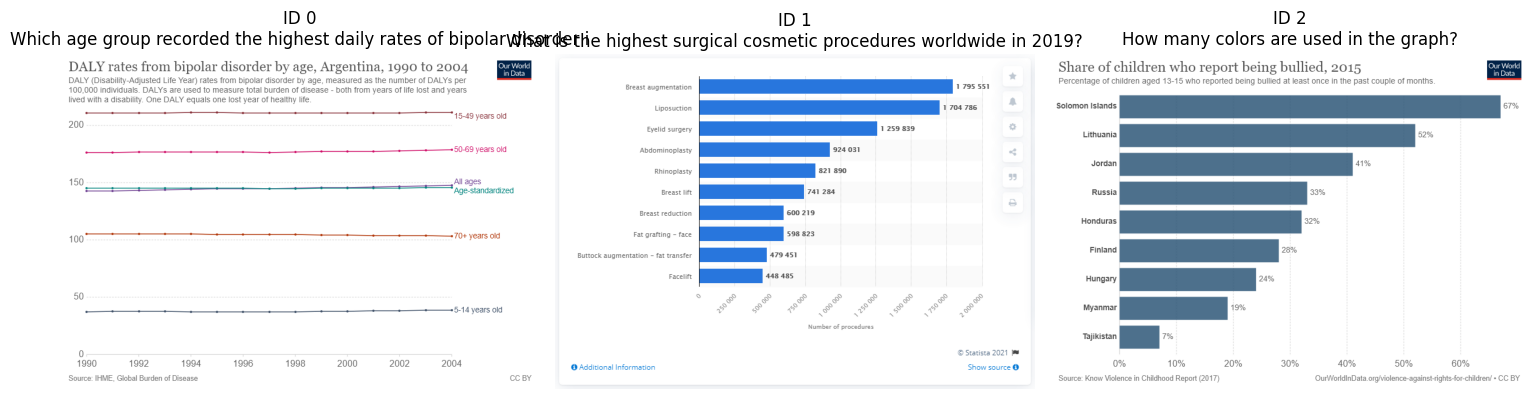

In [ ]:
# @title 8. Inspección visual del corpus
n_show = min(3, len(eval_df))
fig, axes = plt.subplots(1, n_show, figsize=(5*n_show, 4))
if n_show == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, eval_df.head(n_show).iterrows()):
    ax.imshow(row["image"])
    ax.axis("off")
    ax.set_title(f"ID {row['doc_id']}\n{row['question'][:70]}")

plt.tight_layout()
plt.show()


## 5. Sistema A — Text-only RAG

**Pipeline:** Pregunta → BM25 → Top-K tablas → Gemini

BM25 se construye exclusivamente sobre la representación tabular del gráfico. Las preguntas y respuestas no forman parte del índice.


In [ ]:
# @title 9. Índice BM25 y retrieval textual
def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

bm25_corpus = [tokenize(t) for t in corpus_df["table_text"].fillna("")]
bm25 = BM25Okapi(bm25_corpus)

def retrieve_text(query, k=TOP_K):
    scores = bm25.get_scores(tokenize(query))
    ranked = np.argsort(scores)[::-1][:k]
    return [
        {
            "corpus_id": int(i),
            "chart_id": corpus_df.iloc[int(i)]["chart_id"],
            "score": float(scores[i]),
        }
        for i in ranked
    ]

text_retrieval = {}
text_retrieval_latency = {}

for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc="Text retrieval"):
    qid = int(row["doc_id"])
    t0 = time.perf_counter()
    text_retrieval[qid] = retrieve_text(row["question"], TOP_K)
    text_retrieval_latency[qid] = time.perf_counter() - t0

print("Ejemplo:", text_retrieval[int(eval_df.iloc[0]["doc_id"])])


Text retrieval:   0%|          | 0/60 [00:00<?, ?it/s]

Ejemplo: [{'corpus_id': 829, 'chart_id': '16653c9890aa9680', 'score': 14.717135539947943}, {'corpus_id': 298, 'chart_id': 'b3560f9b563e7578', 'score': 13.724942464403197}, {'corpus_id': 990, 'chart_id': 'ae0191146f623cf5', 'score': 12.077400105408943}, {'corpus_id': 10, 'chart_id': '750eda713aa97859', 'score': 11.902980250994045}, {'corpus_id': 537, 'chart_id': '265059a56c7a9a8b', 'score': 11.131571517695242}]


## 6. Sistema B — Multimodal RAG

**Pipeline:** Pregunta → CLIP texto → similitud texto-imagen → Top-K gráficos → Gemini

Los embeddings de imágenes se construyen offline. La latencia de retrieval por consulta incluye la codificación de la pregunta y la búsqueda.


In [ ]:
# @title 10. Cargar CLIP
CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE)
clip_model.eval()

print("CLIP cargado:", CLIP_MODEL_NAME)


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP cargado: openai/clip-vit-base-patch32


In [ ]:
# @title 11. Embeddings de imágenes — índice offline
def image_embeddings(images, batch_size=CLIP_BATCH_SIZE):
    all_embeddings = []

    for start in tqdm(range(0, len(images), batch_size), desc="Image embeddings"):
        batch = images[start:start+batch_size]
        inputs = clip_processor(images=batch, return_tensors="pt", padding=True)
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = clip_model.vision_model(pixel_values=inputs["pixel_values"])
            emb = clip_model.visual_projection(outputs.pooler_output)
            emb = emb / emb.norm(dim=-1, keepdim=True)

        all_embeddings.append(emb.cpu())

    return torch.cat(all_embeddings, dim=0)

image_emb = image_embeddings(corpus_df["image"].tolist())
print("Dimensión:", tuple(image_emb.shape))


Image embeddings:   0%|          | 0/32 [00:00<?, ?it/s]

Dimensión: (1000, 512)


In [ ]:
# @title 12. Retrieval multimodal — incluye codificación de consulta
def query_embedding(query):
    inputs = clip_processor(
        text=[query],
        return_tensors="pt",
        padding=True,
        truncation=True
    )
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = clip_model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )
        emb = clip_model.text_projection(outputs.pooler_output)
        emb = emb / emb.norm(dim=-1, keepdim=True)

    return emb.cpu()[0]

def retrieve_multimodal(query, k=TOP_K):
    q_emb = query_embedding(query)
    scores = torch.mv(image_emb, q_emb)
    ranked = torch.argsort(scores, descending=True)[:k]

    return [
        {
            "corpus_id": int(i),
            "chart_id": corpus_df.iloc[int(i)]["chart_id"],
            "score": float(scores[i]),
        }
        for i in ranked
    ]

multimodal_retrieval = {}
multimodal_retrieval_latency = {}

for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc="Multimodal retrieval"):
    qid = int(row["doc_id"])
    t0 = time.perf_counter()
    multimodal_retrieval[qid] = retrieve_multimodal(row["question"], TOP_K)
    multimodal_retrieval_latency[qid] = time.perf_counter() - t0

print("Ejemplo:", multimodal_retrieval[int(eval_df.iloc[0]["doc_id"])])


Multimodal retrieval:   0%|          | 0/60 [00:00<?, ?it/s]

Ejemplo: [{'corpus_id': 16, 'chart_id': 'efea48d45aea66b2', 'score': 0.3949007987976074}, {'corpus_id': 905, 'chart_id': 'd3d5d3558cbc3fc4', 'score': 0.3126198649406433}, {'corpus_id': 663, 'chart_id': 'b374f773eeea3441', 'score': 0.3079262375831604}, {'corpus_id': 832, 'chart_id': '82583901163e7c96', 'score': 0.30756106972694397}, {'corpus_id': 699, 'chart_id': '1b6aae9275f4f398', 'score': 0.30165183544158936}]


## 7. Métricas de retrieval


In [ ]:
# @title 13. Recall@5 y MRR
def recall_at_k(retrieval_dict, eval_data, k=TOP_K):
    hits = []
    for _, row in eval_data.iterrows():
        qid = int(row["doc_id"])
        gold = int(row["gold_corpus_id"])
        retrieved = [int(r["corpus_id"]) for r in retrieval_dict[qid][:k]]
        hits.append(int(gold in retrieved))
    return float(np.mean(hits))

def mean_reciprocal_rank(retrieval_dict, eval_data):
    reciprocal_ranks = []

    for _, row in eval_data.iterrows():
        qid = int(row["doc_id"])
        gold = int(row["gold_corpus_id"])
        rank = None

        for pos, r in enumerate(retrieval_dict[qid], start=1):
            if int(r["corpus_id"]) == gold:
                rank = pos
                break

        reciprocal_ranks.append(1.0/rank if rank else 0.0)

    return float(np.mean(reciprocal_ranks))

text_recall = recall_at_k(text_retrieval, eval_df, TOP_K)
mm_recall = recall_at_k(multimodal_retrieval, eval_df, TOP_K)
text_mrr = mean_reciprocal_rank(text_retrieval, eval_df)
mm_mrr = mean_reciprocal_rank(multimodal_retrieval, eval_df)

retrieval_results = pd.DataFrame([
    {
        "Sistema": "Text-only RAG",
        "Recall@5": text_recall,
        "MRR": text_mrr,
        "Retrieval latency (s)": np.mean(list(text_retrieval_latency.values())),
    },
    {
        "Sistema": "Multimodal RAG",
        "Recall@5": mm_recall,
        "MRR": mm_mrr,
        "Retrieval latency (s)": np.mean(list(multimodal_retrieval_latency.values())),
    }
])

display(retrieval_results.style.format({
    "Recall@5": "{:.3f}",
    "MRR": "{:.3f}",
    "Retrieval latency (s)": "{:.4f}"
}))


,Sistema,Recall@5,MRR,Retrieval latency (s)
0,Text-only RAG,0.233,0.158,0.0024
1,Multimodal RAG,0.150,0.096,0.0136


## 8. Tipología exploratoria de preguntas

Se utiliza una clasificación **heurística y mutuamente exclusiva** basada en palabras clave. No es una anotación oficial de ChartQA; sirve únicamente para estudiar si la modalidad visual ayuda más en determinados tipos.


In [ ]:
# @title 14. Clasificación heurística
def classify_question(q):
    q = q.lower()

    if re.search(r"\b(highest|lowest|largest|smallest|most|least|more|less|higher|lower|increase|decrease|compared|difference)\b", q):
        return "Comparación"
    if re.search(r"\b(value|amount|number|how many|how much|percent|percentage|rate|total|average)\b", q):
        return "Numérica"
    if re.search(r"\b(year|years|age|group|category|name|who|what year)\b", q):
        return "Etiqueta/temporal"
    if re.search(r"\b(color|colour|bar|line|shape|legend|axis|graph|chart|shown|represented)\b", q):
        return "Visual/estructural"
    return "Otra"

eval_df["question_category"] = eval_df["question"].apply(classify_question)
display(eval_df["question_category"].value_counts().rename_axis("Categoría").to_frame("Casos"))


,Casos
Categoría,
Comparación,22
Visual/estructural,15
Numérica,14
Etiqueta/temporal,6
Otra,3


## 9. Modelo generativo

Ambos sistemas utilizan el mismo modelo generativo: **Gemini 2.5 Flash**.

La respuesta de referencia nunca se proporciona al modelo.


In [ ]:
# @title 15. Configurar Gemini
if RUN_GENERATION:
    from google import genai
    from google.colab import userdata

    api_key = userdata.get("GOOGLE_API_KEY")
    if not api_key:
        raise ValueError(
            "No se encontró GOOGLE_API_KEY. Añádela en Colab > Secrets."
        )

    gemini_client = genai.Client(api_key=api_key)
    print("Gemini configurado:", GEMINI_MODEL)
else:
    gemini_client = None
    print("RUN_GENERATION=False")


Gemini configurado: gemini-3.8-flash


In [ ]:
# @title 16. Funciones de generación y evaluación
def clean_generated_answer(text):
    text = str(text).strip()
    text = re.sub(r"^```.*?```$", "", text, flags=re.S).strip()
    text = re.sub(r"^(answer|respuesta)\s*:\s*", "", text, flags=re.I)
    return text.strip()

def generate_text_rag_answer(question, retrieved):
    parts = []
    for rank, r in enumerate(retrieved, start=1):
        row = corpus_df.iloc[int(r["corpus_id"])]
        parts.append(f"TABLE {rank}\n{row['table_text']}")

    prompt = f"""
Answer the question using ONLY the retrieved table evidence.

Question:
{question}

Retrieved table evidence:
{chr(10).join(parts)}

If the evidence is insufficient, answer:
INSUFFICIENT EVIDENCE

Return only the concise answer, with no explanation.
"""

    response = gemini_client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt
    )
    return clean_generated_answer(response.text)

def generate_multimodal_answer(question, retrieved):
    contents = [f"""
Answer the question using ONLY the retrieved chart images.

Question:
{question}

Inspect the retrieved charts carefully.
Use their visual information, labels, legends, axes and values.

If the evidence is insufficient, answer:
INSUFFICIENT EVIDENCE

Return only the concise answer, with no explanation.
"""]

    for rank, r in enumerate(retrieved, start=1):
        contents.append(f"RETRIEVED CHART {rank}")
        contents.append(corpus_df.iloc[int(r["corpus_id"])]["image"])

    response = gemini_client.models.generate_content(
        model=GEMINI_MODEL,
        contents=contents
    )
    return clean_generated_answer(response.text)

def normalize_answer(x):
    x = str(x).lower().strip()
    x = x.replace(",", "")
    x = re.sub(r"\([^)]*\)", "", x)
    x = re.sub(r"\s+", " ", x)
    x = re.sub(r"[^a-z0-9.%\-+/ ]", "", x)
    return x.strip()

def extract_number(x):
    x = str(x).replace(",", "")
    match = re.search(r"-?\d+(?:\.\d+)?", x)
    return float(match.group()) if match else None

def answer_match(pred, gold_answers, numeric_tol=1e-3):
    p = normalize_answer(pred)

    if p == "insufficient evidence":
        return False

    for gold in gold_answers:
        g = normalize_answer(gold)

        if p == g:
            return True

        pn, gn = extract_number(p), extract_number(g)
        if pn is not None and gn is not None:
            if math.isclose(pn, gn, rel_tol=numeric_tol, abs_tol=numeric_tol):
                return True

    return False


## 10. Validación antes de la ejecución completa

Se ejecuta una consulta individual para comprobar acceso a Gemini, formato del contexto, procesamiento de imágenes y evaluación.


In [ ]:
# @title 17. Prueba de una consulta
if RUN_GENERATION:
    test_row = eval_df.iloc[0]
    qid = int(test_row["doc_id"])

    print("PREGUNTA:")
    print(test_row["question"])
    print("\nGROUND TRUTH:")
    print(test_row["answers"])

    print("\n--- TEXT-ONLY RAG ---")
    test_text = generate_text_rag_answer(test_row["question"], text_retrieval[qid])
    print("Predicción:", test_text)
    print("Correcta:", answer_match(test_text, test_row["answers"]))

    print("\n--- MULTIMODAL RAG ---")
    test_mm = generate_multimodal_answer(test_row["question"], multimodal_retrieval[qid])
    print("Predicción:", test_mm)
    print("Correcta:", answer_match(test_mm, test_row["answers"]))


PREGUNTA:
Which age group recorded the highest daily rates of bipolar disorder in Argentina?

GROUND TRUTH:
['15-49 years old']

--- TEXT-ONLY RAG ---
Predicción: INSUFFICIENT EVIDENCE
Correcta: False

--- MULTIMODAL RAG ---
Predicción: 15-49 years old
Correcta: True


## 11. Evaluación completa

La latencia **end-to-end** se mide desde el inicio del retrieval hasta la respuesta final. Esto corrige la medición anterior en la que se contabilizaba solamente la llamada de generación.


In [ ]:
# @title 18. Ejecutar evaluación completa
def load_cache():
    if USE_GENERATION_CACHE and os.path.exists(CACHE_FILE):
        try:
            with open(CACHE_FILE, "r", encoding="utf-8") as f:
                return json.load(f)
        except Exception:
            return {}
    return {}

def save_cache(cache):
    if USE_GENERATION_CACHE:
        with open(CACHE_FILE, "w", encoding="utf-8") as f:
            json.dump(cache, f, ensure_ascii=False, indent=2)

cache = load_cache()
generation_rows = []

if RUN_GENERATION:
    for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc="Evaluación Gemini"):
        qid = int(row["doc_id"])
        gold_answers = row["answers"]

        # Text-only: generación y tiempo total
        t0 = time.perf_counter()
        key_t = f"{qid}_text"

        if key_t in cache:
            pred_text = cache[key_t]
            text_gen_latency = np.nan
        else:
            gt0 = time.perf_counter()
            pred_text = generate_text_rag_answer(row["question"], text_retrieval[qid])
            text_gen_latency = time.perf_counter() - gt0
            cache[key_t] = pred_text
            save_cache(cache)

        text_e2e = time.perf_counter() - t0

        # Multimodal: generación y tiempo total
        t0 = time.perf_counter()
        key_m = f"{qid}_multimodal"

        if key_m in cache:
            pred_mm = cache[key_m]
            mm_gen_latency = np.nan
        else:
            gt0 = time.perf_counter()
            pred_mm = generate_multimodal_answer(row["question"], multimodal_retrieval[qid])
            mm_gen_latency = time.perf_counter() - gt0
            cache[key_m] = pred_mm
            save_cache(cache)

        mm_e2e = time.perf_counter() - t0

        generation_rows.append({
            "doc_id": qid,
            "chart_id": row["chart_id"],
            "question": row["question"],
            "gold": row["answer"],
            "gold_answers": row["answers"],
            "category": row["question_category"],
            "text_prediction": pred_text,
            "multimodal_prediction": pred_mm,
            "text_correct": answer_match(pred_text, gold_answers),
            "multimodal_correct": answer_match(pred_mm, gold_answers),
            "text_retrieval_latency": text_retrieval_latency[qid],
            "multimodal_retrieval_latency": multimodal_retrieval_latency[qid],
            "text_generation_latency": text_gen_latency,
            "multimodal_generation_latency": mm_gen_latency,
            "text_end_to_end_latency": text_e2e,
            "multimodal_end_to_end_latency": mm_e2e,
        })

    generation_df = pd.DataFrame(generation_rows)
    print("Preguntas evaluadas:", len(generation_df))
    display(generation_df.head(10))
else:
    generation_df = pd.DataFrame()
    print("Generación omitida.")


Evaluación Gemini:   0%|          | 0/60 [00:00<?, ?it/s]

Preguntas evaluadas: 60


,doc_id,chart_id,question,gold,gold_answers,category,text_prediction,multimodal_prediction,text_correct,multimodal_correct,text_retrieval_latency,multimodal_retrieval_latency,text_generation_latency,multimodal_generation_latency,text_end_to_end_latency,multimodal_end_to_end_latency
0,0,efea48d45aea66b2,Which age group recorded the highest daily rat...,15-49 years old,[15-49 years old],Comparación,INSUFFICIENT EVIDENCE,15-49 years old,False,True,0.013092,0.281130,NaN,NaN,0.000006,0.000003
1,1,627acabff8ea7d34,What is the highest surgical cosmetic procedur...,Breast augmentation,[Breast augmentation],Comparación,INSUFFICIENT EVIDENCE,INSUFFICIENT EVIDENCE,False,False,0.002416,0.013869,NaN,NaN,0.000004,0.000002
2,2,9e223942ddec183f,How many colors are used in the graph?,1,[1],Numérica,INSUFFICIENT EVIDENCE,INSUFFICIENT EVIDENCE,False,False,0.002121,0.008365,NaN,NaN,0.000003,0.000002
3,3,c40f2860d1555604,What is the value of the largest bar?,1715,[1715],Comparación,INSUFFICIENT EVIDENCE,INSUFFICIENT EVIDENCE,False,False,0.001853,0.007785,NaN,NaN,0.000003,0.000002
4,4,707bdae2d0d28455,How much is the e commerce sales for companies...,35.6,[35.6],Numérica,INSUFFICIENT EVIDENCE,INSUFFICIENT EVIDENCE,False,False,0.002969,0.010046,NaN,NaN,0.000003,0.000002
5,5,9229c31768d1ebb0,Identify what is referred 61% and 55%?,Hardware,[Hardware],Otra,Hardware (in 2014 and 2020),INSUFFICIENT EVIDENCE,True,False,0.001656,0.008720,NaN,NaN,0.000003,0.000002
6,6,9d449acad55227a1,How man years does the graph represent?,11,[11],Etiqueta/temporal,INSUFFICIENT EVIDENCE,INSUFFICIENT EVIDENCE,False,False,0.001651,0.008507,NaN,NaN,0.000003,0.000002
7,7,46c386bc63a007a0,Which color bar resembles the name of a fruit?,orange,[orange],Etiqueta/temporal,INSUFFICIENT EVIDENCE,Orange,False,True,0.001952,0.008148,NaN,NaN,0.000003,0.000002
8,8,fe976feb0a1a9bc8,What year is represented in the graph?,2014,[2014],Etiqueta/temporal,INSUFFICIENT EVIDENCE,1990,False,False,0.001561,0.007684,NaN,NaN,0.000003,0.000002
9,9,af0c9d8ea0c8d4e5,What is the colour of oppose in the graph?,Light blue,[Light blue],Visual/estructural,INSUFFICIENT EVIDENCE,INSUFFICIENT EVIDENCE,False,False,0.001999,0.009120,NaN,NaN,0.000003,0.000002


## 12. Resultados cuantitativos


In [ ]:
# @title 19. Tabla final de resultados
rows = [
    {
        "Sistema": "Text-only RAG",
        "Recall@5": text_recall,
        "MRR": text_mrr,
        "Retrieval latency (s)": np.mean(list(text_retrieval_latency.values())),
    },
    {
        "Sistema": "Multimodal RAG",
        "Recall@5": mm_recall,
        "MRR": mm_mrr,
        "Retrieval latency (s)": np.mean(list(multimodal_retrieval_latency.values())),
    }
]

if RUN_GENERATION and len(generation_df):
    rows[0]["Answer Accuracy"] = generation_df["text_correct"].mean()
    rows[1]["Answer Accuracy"] = generation_df["multimodal_correct"].mean()
    rows[0]["End-to-end latency (s)"] = generation_df["text_end_to_end_latency"].mean()
    rows[1]["End-to-end latency (s)"] = generation_df["multimodal_end_to_end_latency"].mean()

final_results = pd.DataFrame(rows)

display(final_results.style.format({
    "Recall@5": "{:.3f}",
    "MRR": "{:.3f}",
    "Retrieval latency (s)": "{:.4f}",
    "Answer Accuracy": "{:.3f}",
    "End-to-end latency (s)": "{:.2f}",
}))


,Sistema,Recall@5,MRR,Retrieval latency (s),Answer Accuracy,End-to-end latency (s)
0,Text-only RAG,0.233,0.158,0.0024,0.167,2.05
1,Multimodal RAG,0.150,0.096,0.0136,0.150,4.58


In [ ]:
# @title 20. McNemar exacto
if RUN_GENERATION and len(generation_df):
    b = int(((~generation_df["text_correct"]) & generation_df["multimodal_correct"]).sum())
    c = int(((generation_df["text_correct"]) & (~generation_df["multimodal_correct"])).sum())
    discordant = b + c

    p_value = (
        binomtest(b, discordant, 0.5, alternative="two-sided").pvalue
        if discordant > 0 else 1.0
    )

    print(f"Text incorrecto / Multimodal correcto: {b}")
    print(f"Text correcto / Multimodal incorrecto: {c}")
    print(f"Casos discordantes: {discordant}")
    print(f"McNemar exacto p-value: {p_value:.4f}")
    print(
        "Interpretación α=0.05:",
        "diferencia significativa" if p_value < 0.05
        else "no se observa diferencia estadísticamente significativa"
    )


Text incorrecto / Multimodal correcto: 6
Text correcto / Multimodal incorrecto: 7
Casos discordantes: 13
McNemar exacto p-value: 1.0000
Interpretación α=0.05: no se observa diferencia estadísticamente significativa


In [ ]:
# @title 21. Accuracy por tipo de pregunta
if RUN_GENERATION and len(generation_df):
    by_category = (
        generation_df.groupby("category")
        .agg(
            Casos=("doc_id", "count"),
            Text_Accuracy=("text_correct", "mean"),
            Multimodal_Accuracy=("multimodal_correct", "mean")
        )
        .reset_index()
    )

    by_category["Diferencia_MM_minus_Text"] = (
        by_category["Multimodal_Accuracy"] - by_category["Text_Accuracy"]
    )

    display(by_category.style.format({
        "Text_Accuracy": "{:.3f}",
        "Multimodal_Accuracy": "{:.3f}",
        "Diferencia_MM_minus_Text": "{:+.3f}"
    }))


,category,Casos,Text_Accuracy,Multimodal_Accuracy,Diferencia_MM_minus_Text
0,Comparación,22,0.136,0.182,+0.045
1,Etiqueta/temporal,6,0.167,0.167,+0.000
2,Numérica,14,0.286,0.214,-0.071
3,Otra,3,0.333,0.000,-0.333
4,Visual/estructural,15,0.067,0.067,+0.000


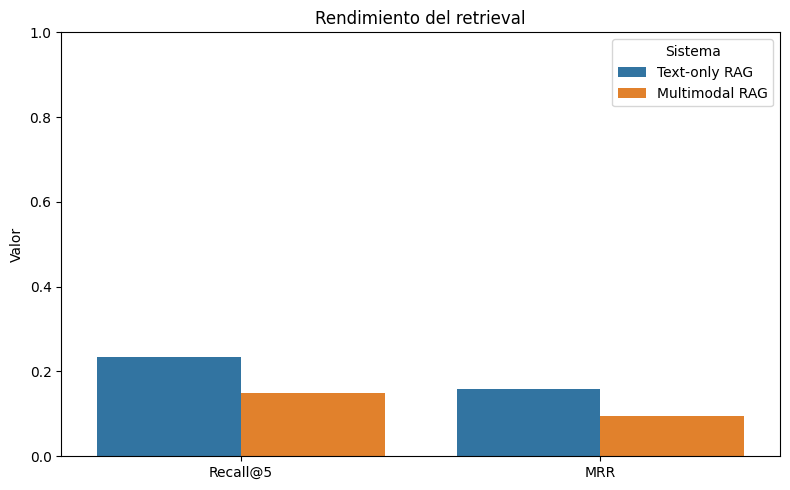

In [ ]:
# @title 22. Figura — Retrieval
plot_data = final_results.melt(
    id_vars="Sistema",
    value_vars=["Recall@5", "MRR"],
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(8,5))
sns.barplot(data=plot_data, x="Métrica", y="Valor", hue="Sistema")
plt.ylim(0,1)
plt.xlabel("")
plt.ylabel("Valor")
plt.title("Rendimiento del retrieval")
plt.tight_layout()
plt.show()


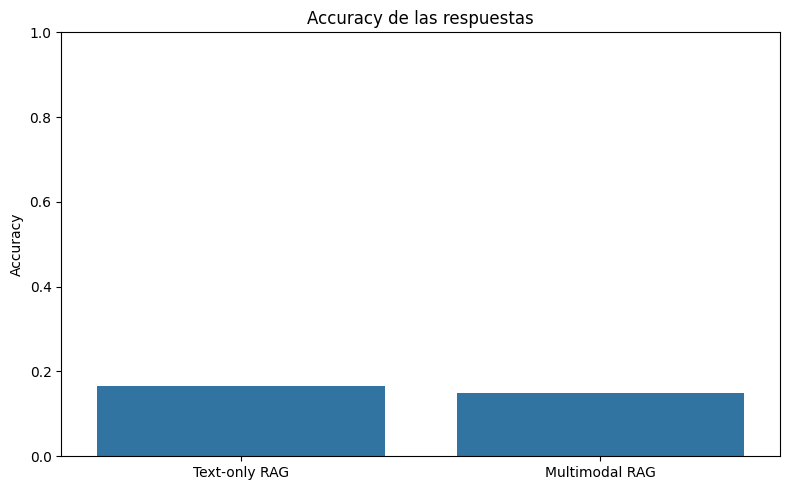

In [ ]:
# @title 23. Figura — Answer Accuracy
if RUN_GENERATION and "Answer Accuracy" in final_results.columns:
    plt.figure(figsize=(8,5))
    sns.barplot(data=final_results, x="Sistema", y="Answer Accuracy")
    plt.ylim(0,1)
    plt.xlabel("")
    plt.ylabel("Accuracy")
    plt.title("Accuracy de las respuestas")
    plt.tight_layout()
    plt.show()


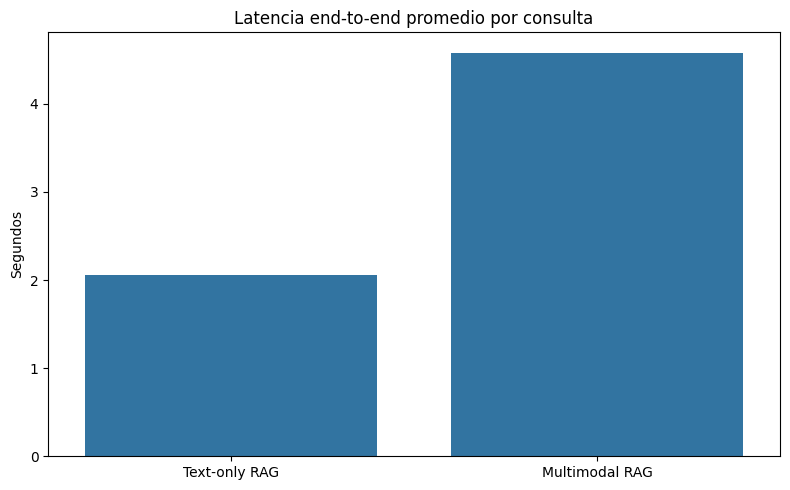

In [ ]:
# @title 24. Figura — Latencia
if RUN_GENERATION and "End-to-end latency (s)" in final_results.columns:
    plt.figure(figsize=(8,5))
    sns.barplot(data=final_results, x="Sistema", y="End-to-end latency (s)")
    plt.xlabel("")
    plt.ylabel("Segundos")
    plt.title("Latencia end-to-end promedio por consulta")
    plt.tight_layout()
    plt.show()


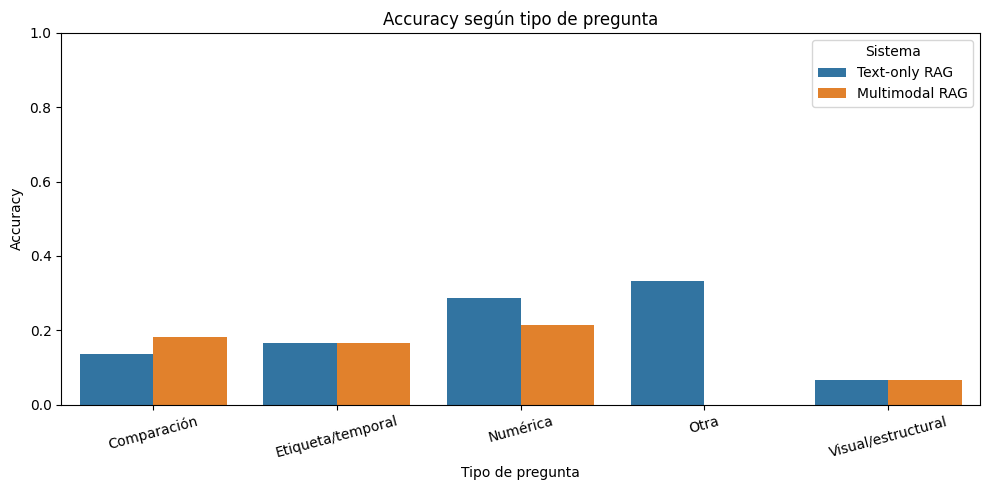

In [ ]:
# @title 25. Figura — Accuracy por tipo
if RUN_GENERATION and len(generation_df):
    plot_cat = by_category.melt(
        id_vars=["category", "Casos"],
        value_vars=["Text_Accuracy", "Multimodal_Accuracy"],
        var_name="Sistema",
        value_name="Accuracy"
    )

    plot_cat["Sistema"] = plot_cat["Sistema"].map({
        "Text_Accuracy": "Text-only RAG",
        "Multimodal_Accuracy": "Multimodal RAG"
    })

    plt.figure(figsize=(10,5))
    sns.barplot(data=plot_cat, x="category", y="Accuracy", hue="Sistema")
    plt.ylim(0,1)
    plt.xlabel("Tipo de pregunta")
    plt.ylabel("Accuracy")
    plt.title("Accuracy según tipo de pregunta")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


## 13. Análisis caso a caso


,Resultado,Casos
0,Ambos aciertan,3
1,Multimodal mejora,6
2,Multimodal empeora,7
3,Ambos fallan,44


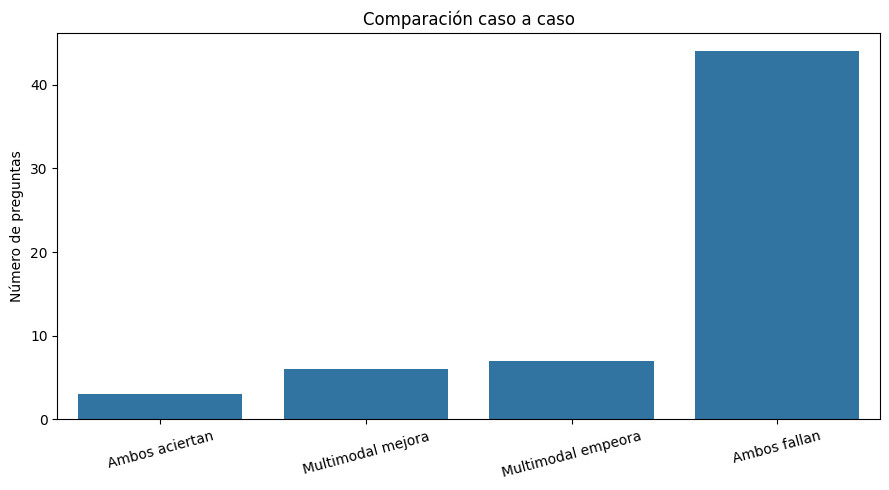

In [ ]:
# @title 26. Comparación caso a caso
if RUN_GENERATION and len(generation_df):
    def outcome(row):
        if row["text_correct"] and row["multimodal_correct"]:
            return "Ambos aciertan"
        if not row["text_correct"] and row["multimodal_correct"]:
            return "Multimodal mejora"
        if row["text_correct"] and not row["multimodal_correct"]:
            return "Multimodal empeora"
        return "Ambos fallan"

    generation_df["outcome"] = generation_df.apply(outcome, axis=1)

    outcome_counts = (
        generation_df["outcome"].value_counts()
        .reindex(
            ["Ambos aciertan", "Multimodal mejora",
             "Multimodal empeora", "Ambos fallan"],
            fill_value=0
        )
        .reset_index()
    )
    outcome_counts.columns = ["Resultado", "Casos"]

    display(outcome_counts)

    plt.figure(figsize=(9,5))
    sns.barplot(data=outcome_counts, x="Resultado", y="Casos")
    plt.xlabel("")
    plt.ylabel("Número de preguntas")
    plt.title("Comparación caso a caso")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


In [ ]:
# @title 27. Casos donde Multimodal mejora
if RUN_GENERATION and len(generation_df):
    improved = generation_df[
        (~generation_df["text_correct"]) &
        (generation_df["multimodal_correct"])
    ][[
        "doc_id", "category", "question", "gold",
        "text_prediction", "multimodal_prediction"
    ]]
    display(improved)


,doc_id,category,question,gold,text_prediction,multimodal_prediction
0,0,Comparación,Which age group recorded the highest daily rat...,15-49 years old,INSUFFICIENT EVIDENCE,15-49 years old
7,7,Etiqueta/temporal,Which color bar resembles the name of a fruit?,orange,INSUFFICIENT EVIDENCE,Orange
12,12,Comparación,Which year recorded the highest suicide rates ...,1996,INSUFFICIENT EVIDENCE,1996
15,15,Comparación,In which year was the death rate due to unsafe...,2000,INSUFFICIENT EVIDENCE,2000
27,27,Visual/estructural,Is the Pie chart divided into 3 segment?,Yes,No,Yes
33,33,Numérica,Which year saw the maximum change in the death...,2010,INSUFFICIENT EVIDENCE,2010


In [ ]:
# @title 28. Casos donde Multimodal empeora
if RUN_GENERATION and len(generation_df):
    worsened = generation_df[
        (generation_df["text_correct"]) &
        (~generation_df["multimodal_correct"])
    ][[
        "doc_id", "category", "question", "gold",
        "text_prediction", "multimodal_prediction"
    ]]
    display(worsened)


,doc_id,category,question,gold,text_prediction,multimodal_prediction
5,5,Otra,Identify what is referred 61% and 55%?,Hardware,Hardware (in 2014 and 2020),INSUFFICIENT EVIDENCE
11,11,Comparación,What is the highest percentage recorded in Hap...,69,69%,INSUFFICIENT EVIDENCE
21,21,Comparación,Which year has the highest number of all-elect...,2020,2020,INSUFFICIENT EVIDENCE
22,22,Etiqueta/temporal,"In the chart, Lesbian women data shows 28 and ...",Dating,Dating,INSUFFICIENT EVIDENCE
43,43,Numérica,What is the percentage of households with Stan...,18,18%,INSUFFICIENT EVIDENCE
48,48,Visual/estructural,Which repsone has the biggest slice of the graph?,As much as before the lockdown,As much as before the lockdown,60–69 years
51,51,Numérica,What is the value (in billion euros) of the In...,9.2,9.2,INSUFFICIENT EVIDENCE


PREGUNTA:
Which age group recorded the highest daily rates of bipolar disorder in Argentina?

GROUND TRUTH:
['15-49 years old']

GRÁFICO:


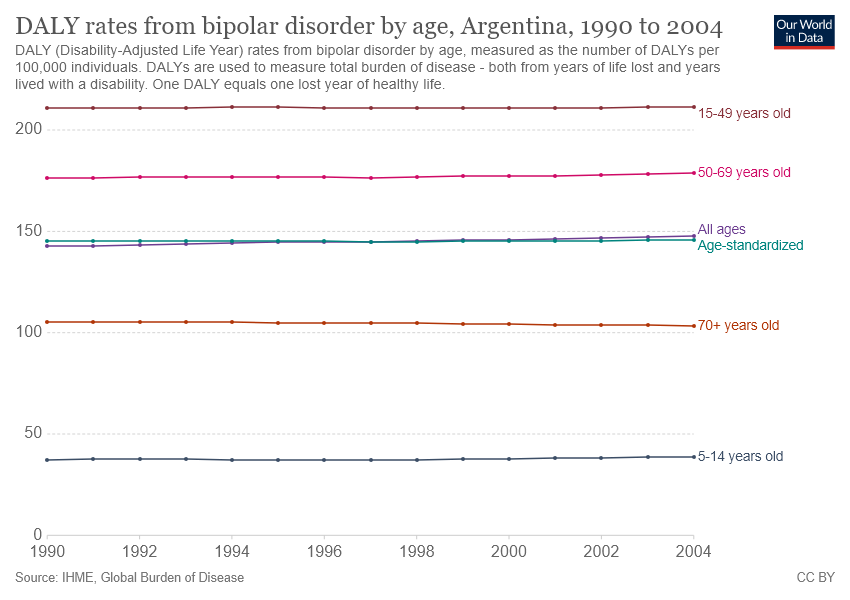


TOP-K TEXT-ONLY:
1. chart=16653c9890aa9680 score=14.7171
2. chart=b3560f9b563e7578 score=13.7249
3. chart=ae0191146f623cf5 score=12.0774
4. chart=750eda713aa97859 score=11.9030
5. chart=265059a56c7a9a8b score=11.1316

TOP-K MULTIMODAL:
1. chart=efea48d45aea66b2 score=0.3949
2. chart=d3d5d3558cbc3fc4 score=0.3126
3. chart=b374f773eeea3441 score=0.3079
4. chart=82583901163e7c96 score=0.3076
5. chart=1b6aae9275f4f398 score=0.3017

TEXT-ONLY: INSUFFICIENT EVIDENCE
MULTIMODAL: 15-49 years old
Text correcto: False
Multimodal correcto: True


In [ ]:
# @title 29. Caso cualitativo configurable
def show_case(doc_id):
    row = eval_df[eval_df["doc_id"] == int(doc_id)].iloc[0]

    print("="*90)
    print("PREGUNTA:")
    print(row["question"])
    print("\nGROUND TRUTH:")
    print(row["answers"])

    print("\nGRÁFICO:")
    display(row["image"])

    print("\nTOP-K TEXT-ONLY:")
    for rank, r in enumerate(text_retrieval[int(doc_id)], start=1):
        print(f"{rank}. chart={r['chart_id']} score={r['score']:.4f}")

    print("\nTOP-K MULTIMODAL:")
    for rank, r in enumerate(multimodal_retrieval[int(doc_id)], start=1):
        print(f"{rank}. chart={r['chart_id']} score={r['score']:.4f}")

    if RUN_GENERATION and len(generation_df):
        g = generation_df[generation_df["doc_id"] == int(doc_id)].iloc[0]
        print("\nTEXT-ONLY:", g["text_prediction"])
        print("MULTIMODAL:", g["multimodal_prediction"])
        print("Text correcto:", bool(g["text_correct"]))
        print("Multimodal correcto:", bool(g["multimodal_correct"]))

CASE_ID = int(eval_df.iloc[0]["doc_id"])
show_case(CASE_ID)


## 14. Limitaciones

- Se evalúan hasta 60 casos.
- El corpus está limitado a 1000 gráficos.
- BM25 es un baseline léxico.
- CLIP es un baseline cross-modal generalista y no un modelo especializado en comprensión de gráficos.
- La clasificación por tipo de pregunta es heurística.
- Gemini introduce variabilidad en la generación.
- La evaluación de respuestas utiliza una normalización reproducible, pero no sustituye todas las variantes del evaluador oficial de ChartQA.
- Los resultados son específicos de esta configuración y no permiten afirmar superioridad general de una arquitectura.


# 15. Conclusiones

La conclusión debe formularse a partir de los resultados obtenidos.

Una formulación defendible para la exposición es:

> **La incorporación de evidencia visual no garantiza por sí sola una mejora del RAG. En este experimento, los sistemas presentan comportamientos diferentes en retrieval y generación. El análisis caso a caso permite identificar situaciones en las que la evidencia visual aporta información que el sistema textual no recupera, pero también casos en los que la recuperación cross-modal introduce errores.**

Esto conecta con el reto central de *PaperIA*: la incorporación de múltiples modalidades requiere resolver adecuadamente la **recuperación y alineación entre la consulta y la evidencia relevante**, no simplemente añadir imágenes al pipeline.


In [ ]:
# @title 30. Resumen para la exposición
print("========== RESUMEN DEL EXPERIMENTO ==========")
print(f"Recall@5 — Text-only:  {text_recall:.3f}")
print(f"Recall@5 — Multimodal: {mm_recall:.3f}")
print(f"MRR — Text-only:       {text_mrr:.3f}")
print(f"MRR — Multimodal:      {mm_mrr:.3f}")

if RUN_GENERATION and len(generation_df):
    text_acc = generation_df["text_correct"].mean()
    mm_acc = generation_df["multimodal_correct"].mean()

    print(f"Accuracy — Text-only:  {text_acc:.3f}")
    print(f"Accuracy — Multimodal: {mm_acc:.3f}")
    print(f"Δ Accuracy (MM - Text): {mm_acc-text_acc:+.3f}")

    b = ((~generation_df["text_correct"]) & generation_df["multimodal_correct"]).sum()
    c = ((generation_df["text_correct"]) & (~generation_df["multimodal_correct"])).sum()
    print(f"Multimodal mejora: {b}")
    print(f"Multimodal empeora: {c}")


========== RESUMEN DEL EXPERIMENTO ==========
Recall@5 — Text-only:  0.233
Recall@5 — Multimodal: 0.150
MRR — Text-only:       0.158
MRR — Multimodal:      0.096
Accuracy — Text-only:  0.167
Accuracy — Multimodal: 0.150
Δ Accuracy (MM - Text): -0.017
Multimodal mejora: 6
Multimodal empeora: 7


## 16. Exportación

El notebook exporta las tablas para utilizarlas en las diapositivas y para compartir los resultados con el profesor.


In [ ]:
# @title 31. Exportar resultados
final_results.to_csv("/content/chartqa_final_results.csv", index=False)

if RUN_GENERATION and len(generation_df):
    generation_df.to_csv("/content/chartqa_generation_results.csv", index=False)
    by_category.to_csv("/content/chartqa_accuracy_by_category.csv", index=False)
    outcome_counts.to_csv("/content/chartqa_outcomes.csv", index=False)

print("Exportación completada.")


Exportación completada.


## 17. Fuente conceptual

**PaperIA:** *Ask in Any Modality: A Comprehensive Survey on Multimodal Retrieval-Augmented Generation*.

El paper se utiliza como fuente conceptual para motivar el problema y los retos de M-RAG. Los resultados numéricos pertenecen exclusivamente a este experimento.
